# LatAm FX volatility: cones, risk premium and relative value

A worked notebook that rebuilds the analysis step by step, so you can check every number and change any assumption.

**Contents**
1. Setup and loading the Bloomberg export
2. Data quality: holidays, big moves, stale prints
3. Realized volatility, done carefully
4. Option basics you need: vega, and why short vol P&L ≈ vega × (implied − realized)
5. The volatility cone
6. Skew snapshot: risk reversals and butterflies vs history
7. The volatility risk premium (VRP), measured properly
8. Across LatAm: comparing pairs, and the equal-vega basket
9. Relative value: a vega-neutral long/short backtest with daily marking and costs
10. Diagnosing the result: where the P&L comes from
11. Checklist before you show this to a vol trader, and exercises

**How to use it.** Put `latam_fx.xlsx` in the same folder and run top to bottom (the backtest cells take a minute or two). Cells marked **Try it** are good places to change a parameter and see what moves.

## 1. Setup and loading the Bloomberg export

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import erf, sqrt, exp, pi

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True,
                     "grid.linestyle": "--", "grid.alpha": .5})

FILE   = "latam_fx.xlsx"
PAIRS  = ["COP", "MXN", "BRL", "CLP", "PEN"]
TENORS = {"3M": 3, "6M": 6, "9M": 9, "1Y": 12}     # tenor -> months
ANN    = 252                                       # trading days per year

Each sheet is a raw Bloomberg BDH export: tickers sit in row 6, data starts in row 9, dates in column B. The helper below turns each sheet into a tidy frame with short column names:

| column | meaning | units |
|---|---|---|
| `spot` | USD/xxx spot | local currency per USD |
| `atm_3M` … `atm_1Y` | at-the-money implied vol | vol %, e.g. 14.5 |
| `rr_3M`, `rr_6M`, `rr_1Y` | 25-delta risk reversal: vol of 25d USD call − 25d USD put | vol points |
| `bf_3M`, `bf_6M`, `bf_1Y` | 15-delta butterfly: average 15d wing vol − ATM vol | vol points |

A positive RR means USD calls (local-currency weakness) are priced above USD puts, which is normal for EM currencies. The BF measures how expensive both wings are relative to ATM, i.e. how fat-tailed the market thinks the distribution is.

In [2]:
def load_sheet(raw):
    tickers = raw.iloc[5, 2:13].tolist()
    df = raw.iloc[8:, 1:13].copy()
    df.columns = ["date"] + tickers
    df["date"] = pd.to_datetime(df["date"])
    return df.set_index("date").apply(pd.to_numeric, errors="coerce")

def tidy(df, pair):
    cols = {c.upper(): c for c in df.columns}          # tickers mix '1Y' and '1y'
    out = pd.DataFrame(index=df.index)
    out["spot"] = df[cols[f"USD{pair} CURNCY"]]
    for t in TENORS:
        out[f"atm_{t}"] = df[cols[f"USD{pair}V{t} BGN CURNCY"]]
    for t in ["3M", "6M", "1Y"]:
        out[f"rr_{t}"] = df[cols[f"USD{pair}25R{t} BGN CURNCY"]]
        out[f"bf_{t}"] = df[cols[f"USD{pair}15B{t} BGN CURNCY"]]
    return out

raw  = pd.read_excel(FILE, sheet_name=None, header=None)
data = {p: tidy(load_sheet(raw[p]), p) for p in PAIRS}
print(data["COP"].tail(3).T)

date    2026-10-22  2026-10-23  2026-10-26
spot     3174.6300   3146.2300   3141.3500
atm_3M     14.5000     14.3450     14.5250
atm_6M     14.3950     14.4400     14.4650
atm_9M     14.3775     14.3900     14.4050
atm_1Y     14.4325     14.4050     14.4475
rr_3M       2.6950      2.6800      2.6600
bf_3M       1.2425      1.2425      1.2550
rr_6M       2.5950      2.6600      2.6300
bf_6M       1.3275      1.3175      1.3600
rr_1Y       2.6750      2.6900      2.6300
bf_1Y       1.4550      1.4550      1.4500


## 2. Data quality: always look before you compute

Three things to check in any Bloomberg FX history:

* **Holidays.** The export is on a weekday calendar. On a local holiday Bloomberg repeats the previous price, so the return is exactly zero. Those fake zeros drag realized vol down and make implied look richer than it is.
* **Huge moves.** Real events (elections, devaluations) or bad ticks. You need to know which.
* **Stale prints.** Spot and vol snapshots are not always taken at the same time.

In [3]:
rows = []
for p in PAIRS:
    s = data[p]["spot"]
    r = np.log(s).diff()
    big = r.abs().idxmax()
    rows.append(dict(pair=p, obs=len(s), missing=int(data[p].isna().sum().sum()),
                     zero_change_days=int((s.diff() == 0).sum()),
                     biggest_move_date=big.date(), biggest_move_pct=round(r[big] * 100, 2)))
print(pd.DataFrame(rows).set_index("pair"))
print()
print(data["BRL"][["spot", "atm_3M", "rr_3M"]].tail(4))

       obs  missing  zero_change_days biggest_move_date  biggest_move_pct
pair                                                                     
COP   3344        0               223        2014-12-02              6.02
MXN   3344        0                 3        2016-11-09              7.98
BRL   3344        0               142        2026-10-26              8.48
CLP   3344        0               130        2022-07-15             -7.37
PEN   3344        0               200        2021-07-30              3.55

              spot  atm_3M   rr_3M
date                              
2026-10-21  5.0240  17.765  5.8450
2026-10-22  5.0451  18.170  6.1300
2026-10-23  4.9790  16.165  3.0725
2026-10-26  5.4198  16.250  2.8300


**Reading this**

* COP (~223), PEN (~200), BRL and CLP have many zero-change days, roughly one per local holiday. MXN has almost none, because USDMXN trades through Mexican holidays.
* BRL's biggest move is the latest row: spot +8.5% on 26 Oct 2026, the day after Lula's surprise runoff win. The move is real. But BRL 3M implied barely changed (16.17 → 16.25) on a day when it should have jumped. That looks like a stale vol snapshot, so treat today's BRL implied readings with suspicion.

**Rule we use from here on:** drop zero-change days and annualize with the number of genuine trading days.

## 3. Realized volatility, done carefully

In [4]:
def log_returns(spot):
    s = spot[spot.diff() != 0]                 # drop forward-filled holidays
    return np.log(s).diff().dropna()

def realized_vol(r, zero_mean=True):
    x = r if zero_mean else r - r.mean()
    return np.sqrt((x ** 2).mean() * ANN) * 100

rets = {p: log_returns(data[p]["spot"]) for p in PAIRS}

cop_with_zeros = np.log(data["COP"]["spot"]).diff().dropna()
print(f"COP full-sample realized vol, holidays kept   : {realized_vol(cop_with_zeros):.2f}%")
print(f"COP full-sample realized vol, holidays dropped: {realized_vol(rets['COP']):.2f}%")

COP full-sample realized vol, holidays kept   : 13.43%
COP full-sample realized vol, holidays dropped: 13.90%


Keeping the holiday zeros understates COP realized vol by roughly half a vol point. That is about the same size as the whole risk premium we are trying to measure, so this detail matters.

Two other conventions:

* **Zero mean.** We use $\sigma = \sqrt{\tfrac{252}{n}\sum r_i^2}$ rather than subtracting the sample mean. That is how variance swaps and option traders measure realized vol, and over short windows the drift is noise anyway.
* **Close-to-close Bloomberg spot.** For the non-deliverable pairs (COP, BRL, CLP, PEN) options settle against official fixings (TRM for COP, PTAX for BRL and so on). A stricter study would measure realized vol on the fixing series.

## 4. Option basics: vega, and why short vol P&L ≈ vega × (implied − realized)

**Vega** is the dollar P&L of an option position for a 1 vol-point move in implied vol. For an at-the-money straddle there is a handy rule of thumb:

$$\text{vega per vol point} \approx 0.8 \times \sqrt{T} \times \text{notional} / 100$$

Below we check it against Black-Scholes (zero rates for simplicity; FX options use Garman-Kohlhagen, where the two interest rates shift the forward but barely change ATM vega).

In [5]:
def N(x): return 0.5 * (1 + erf(x / sqrt(2)))
def npdf(x): return exp(-x * x / 2) / sqrt(2 * pi)

def straddle(S, K, T, vol):
    # Black-Scholes straddle with zero rates: price, delta, vega per 1 vol point
    d1 = (np.log(S / K) + 0.5 * vol**2 * T) / (vol * np.sqrt(T)); d2 = d1 - vol * np.sqrt(T)
    Nv = np.vectorize(N)
    call = S * Nv(d1) - K * Nv(d2); put = call - S + K
    delta = 2 * Nv(d1) - 1
    vega = 2 * S * np.sqrt(T) * np.exp(-d1**2 / 2) / np.sqrt(2 * np.pi) / 100
    return call + put, delta, vega

notional = 1_000_000
for tenor, T in [("3M", .25), ("6M", .5), ("1Y", 1.0)]:
    _, _, v = straddle(1.0, 1.0, T, 0.145)
    print(f"{tenor}: Black-Scholes vega ${v * notional:,.0f} per vol pt   rule of thumb ${0.8 * np.sqrt(T) * notional / 100:,.0f}")

3M: Black-Scholes vega $3,987 per vol pt   rule of thumb $4,000
6M: Black-Scholes vega $5,634 per vol pt   rule of thumb $5,657
1Y: Black-Scholes vega $7,958 per vol pt   rule of thumb $8,000


So a 3M ATM straddle on \$1m has about \$4,000 of vega. In USD terms this barely depends on the currency pair or the vol level, which is why "equal vega" across pairs at the same tenor is close to "equal USD notional".

**Why the P&L of a delta-hedged short straddle ≈ vega × (implied − realized).** You sell the straddle at the implied vol and hedge its delta every day. Each day you earn time decay (theta) and lose on the convexity (gamma) of the move that happened. Theta is priced off implied vol; gamma losses depend on realized moves. Over the life of the trade, these net to roughly vega × (implied − realized).

The simulation below checks this: sell a 3M straddle at 15% implied, delta-hedge daily, and let the market realize different vols on different paths.

correlation between simulated P&L and the approximation: 0.92


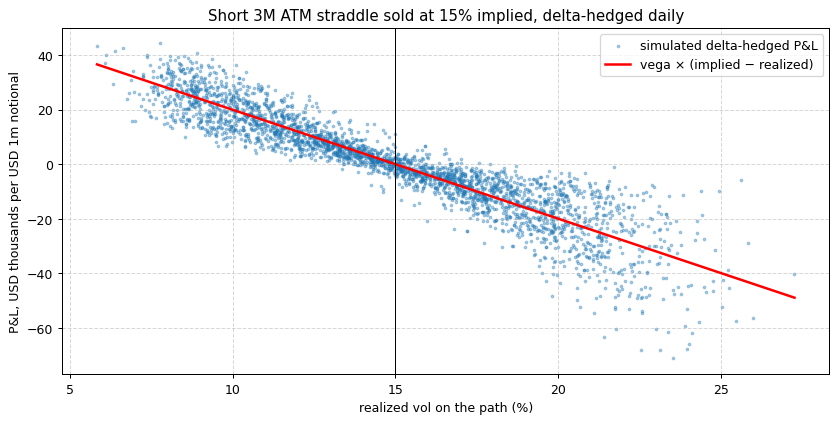

In [6]:
rng = np.random.default_rng(0)
n_paths, n_steps, T, iv = 3000, 63, 0.25, 0.15
dt = T / n_steps
true_vol = rng.uniform(0.08, 0.22, n_paths)                   # each path realizes a different vol
z = rng.standard_normal((n_paths, n_steps))
logS = np.cumsum(true_vol[:, None] * np.sqrt(dt) * z - 0.5 * true_vol[:, None]**2 * dt, axis=1)
S = np.hstack([np.ones((n_paths, 1)), np.exp(logS)])          # spot paths starting at 1.0

premium, _, vega0 = straddle(1.0, 1.0, T, iv)
hedge_pnl = np.zeros(n_paths)
for k in range(n_steps):                                      # short straddle -> hold +delta of spot
    tau = T - k * dt
    _, delta, _ = straddle(S[:, k], 1.0, tau, iv)
    hedge_pnl += delta * (S[:, k + 1] - S[:, k])
payoff = np.abs(S[:, -1] - 1.0)
pnl = (premium - payoff + hedge_pnl) * notional

rv_path = np.sqrt((np.diff(np.log(S), axis=1) ** 2).sum(axis=1) / T) * 100
approx = vega0 * notional * (iv * 100 - rv_path)

fig, ax = plt.subplots()
ax.scatter(rv_path, pnl / 1e3, s=4, alpha=.35, label="simulated delta-hedged P&L")
xs = np.sort(rv_path); ax.plot(xs, vega0 * notional * (iv * 100 - xs) / 1e3, "r", lw=2, label="vega × (implied − realized)")
ax.axvline(iv * 100, color="k", lw=.8)
ax.set_xlabel("realized vol on the path (%)"); ax.set_ylabel("P&L, USD thousands per USD 1m notional")
ax.set_title("Short 3M ATM straddle sold at 15% implied, delta-hedged daily"); ax.legend(); plt.show()
print(f"correlation between simulated P&L and the approximation: {np.corrcoef(pnl, approx)[0, 1]:.2f}")

The red line explains most of the result, but the cloud around it is wide. The scatter comes from **path dependence**: gamma is largest when spot is near the strike, so a big move late in the trade, close to the strike, costs more than the same move early on or far from the strike. Two paths with identical realized vol can have quite different P&L.

Keep this in mind: every VRP number in this notebook uses implied − realized as a stand-in for the true straddle P&L.

## 5. The volatility cone

For each window length N (x-axis), compute the annualized realized vol of **every** N-day window in history, then plot the max, min, mean and ±1/±2 standard deviations. The current ATM implied vols go on top as dots at their tenor in trading days (3M ≈ 63, 6M ≈ 126, 9M ≈ 189, 1Y ≈ 252).

* Short windows have a wide cone: a few big days can make one month very volatile or very calm.
* Long windows converge to the long-run level, because shocks average out and vol mean-reverts.
* A dot near the top of the cone says options are priced for an unusually turbulent period; near the bottom, an unusually calm one.

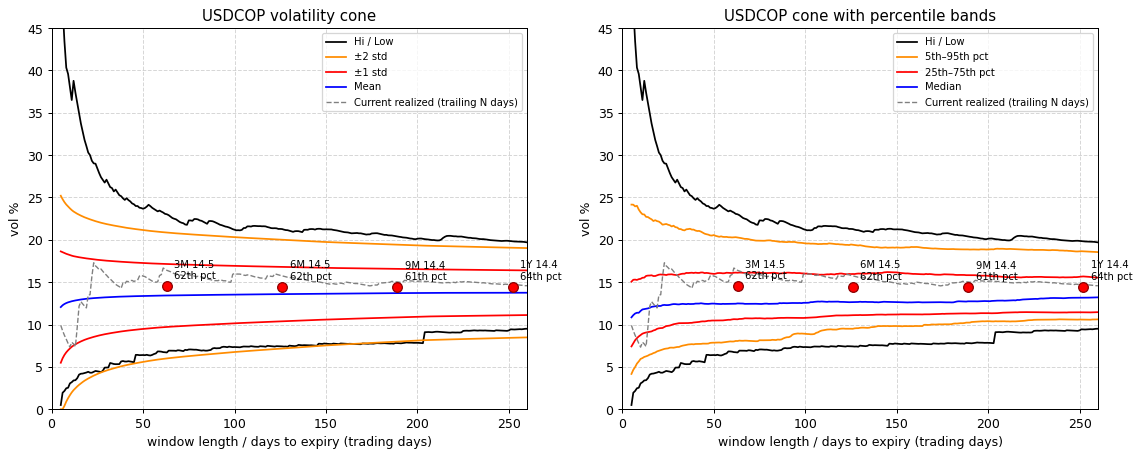

In [7]:
TD = {"3M": 63, "6M": 126, "9M": 189, "1Y": 252}

def cone(r, max_n=260):
    rows = []
    for n in range(5, max_n + 1):
        rv = r.rolling(n).std().dropna() * np.sqrt(ANN) * 100
        rows.append(dict(n=n, hi=rv.max(), lo=rv.min(), mean=rv.mean(), std=rv.std(),
                         p05=rv.quantile(.05), p25=rv.quantile(.25), p50=rv.median(),
                         p75=rv.quantile(.75), p95=rv.quantile(.95), current=rv.iloc[-1]))
    return pd.DataFrame(rows).set_index("n")

def plot_cone(ax, pair, percentiles=False):
    c = cone(rets[pair])
    ax.plot(c.index, c.hi, "k", lw=1.4, label="Hi / Low"); ax.plot(c.index, c.lo, "k", lw=1.4)
    if percentiles:
        bands = [("p95", "p05", "darkorange", "5th–95th pct"), ("p75", "p25", "red", "25th–75th pct")]
        mid, mid_label = c.p50, "Median"
    else:
        bands = [(None, None, "darkorange", "±2 std"), (None, None, "red", "±1 std")]
        mid, mid_label = c["mean"], "Mean"
    for (u, l, colr, lab), k in zip(bands, [2, 1]):
        up = c[u] if percentiles else c["mean"] + k * c["std"]
        dn = c[l] if percentiles else (c["mean"] - k * c["std"]).clip(lower=0)
        ax.plot(c.index, up, color=colr, lw=1.4, label=lab); ax.plot(c.index, dn, color=colr, lw=1.4)
    ax.plot(c.index, mid, "b", lw=1.4, label=mid_label)
    ax.plot(c.index, c.current, color="grey", ls="--", lw=1.1, label="Current realized (trailing N days)")
    for t, n in TD.items():
        v = data[pair][f"atm_{t}"].iloc[-1]
        pct = (rets[pair].rolling(n).std().dropna() * np.sqrt(ANN) * 100 < v).mean() * 100
        ax.scatter(n, v, s=60, color="red", edgecolor="darkred", zorder=5)
        ax.annotate(f"{t} {v:.1f}\n{pct:.0f}th pct", (n, v), xytext=(6, 6), textcoords="offset points", fontsize=8)
    ax.set_xlim(0, 260); ax.set_ylim(0, min(c.hi.max() * 1.05, 45))
    ax.set_xlabel("window length / days to expiry (trading days)"); ax.set_ylabel("vol %"); ax.set_title(f"USD{pair} volatility cone")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_cone(axes[0], "COP"); plot_cone(axes[1], "COP", percentiles=True)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
axes[1].set_title("USDCOP cone with percentile bands"); plt.show()

**Why the percentile version is more honest.** Vol is skewed to the upside: it can spike to 40% but cannot go below zero. The ±2 std line on the left drops to zero at short windows, which is impossible. Percentiles respect the skew.

**Try it:** change `"COP"` to `"PEN"`. PEN implied sits near the top of its cone because the central bank keeps realized vol very low, while options still price political tail risk.

## 6. Skew snapshot: risk reversals and butterflies vs their own history

Realized vol has no skew equivalent, so skew gets its own comparison: where does today's RR or BF sit within its own 2014–2026 history?

In [8]:
def skew_table(pair):
    rows = []
    for kind in ["rr", "bf"]:
        for t in ["3M", "6M", "1Y"]:
            h = data[pair][f"{kind}_{t}"].dropna(); cur = h.iloc[-1]
            rows.append(dict(metric=f"{kind.upper()} {t}", current=cur, median=h.median(),
                             p05=h.quantile(.05), p95=h.quantile(.95),
                             pctile=(h < cur).mean() * 100, z=(cur - h.mean()) / h.std()))
    return pd.DataFrame(rows).set_index("metric").round(2)

print(skew_table("COP"))

        current  median   p05   p95  pctile     z
metric                                           
RR 3M      2.66    2.05  1.40  2.76   92.61  1.32
RR 6M      2.63    2.25  1.59  2.83   80.44  0.99
RR 1Y      2.63    2.47  1.81  3.09   63.73  0.44
BF 3M      1.25    1.06  0.78  1.39   79.87  0.80
BF 6M      1.36    1.28  0.93  1.58   65.22  0.38
BF 1Y      1.45    1.60  1.13  1.91   27.96 -0.46


COP 3M RR sits around its 93rd percentile while 1Y is near its median: front-end protection against peso weakness is unusually bid. Historically the RR curve slopes up (1Y above 3M), so a flat curve is itself the anomaly. That is a skew *term-structure* observation, not a level one.

## 7. The volatility risk premium (VRP)

Two definitions, and it matters which one you use:

* **Ex-post VRP** = implied vol on day *t* − realized vol over the option's life (t to t + tenor). This is what a seller of delta-hedged ATM vol actually earned (section 4). It is only known after expiry, so it measures *profitability*, not a tradable signal.
* **Ex-ante VRP** = implied vol on day *t* − realized vol over the *previous* tenor. Known on day t, so it is a candidate *signal*.

The function below computes both efficiently with cumulative sums of squared returns.

In [9]:
def window_rv(r, starts, ends):
    # realized vol over (start, end] for many windows at once
    idx = r.index; c = np.concatenate([[0.0], np.cumsum(r.values ** 2)])
    a = idx.searchsorted(starts, side="right"); b = idx.searchsorted(ends, side="right")
    n = np.maximum(b - a, 1)
    return np.sqrt((c[b] - c[a]) / n * ANN) * 100

def vrp_frame(pair, tenor):
    r = rets[pair]; dates = r.index; m = TENORS[tenor]
    iv = data[pair][f"atm_{tenor}"].reindex(dates)
    ends = dates + pd.DateOffset(months=m); ok = ends <= dates[-1]
    starts = dates - pd.DateOffset(months=m); ok2 = starts >= dates[0]
    out = pd.DataFrame(index=dates)
    out["iv"] = iv
    out.loc[ok, "rv_fwd"] = window_rv(r, dates[ok], ends[ok])
    out.loc[ok2, "rv_trail"] = window_rv(r, starts[ok2], dates[ok2])
    out["vrp_expost"] = out.iv - out.rv_fwd
    out["vrp_exante"] = out.iv - out.rv_trail
    return out

V = {p: {t: vrp_frame(p, t) for t in TENORS} for p in PAIRS}
print(V["COP"]["3M"].dropna().tail(3).round(2))

               iv  rv_fwd  rv_trail  vrp_expost  vrp_exante
date                                                       
2026-07-22  13.14   16.15     15.74       -3.01       -2.59
2026-07-23  13.09   16.24     15.74       -3.15       -2.65
2026-07-24  13.16   16.32     15.79       -3.16       -2.63


### Measuring profitability without fooling yourself

* **Overlapping trades.** A 3M trade opened each day overlaps with the 62 opened just before it, so daily observations are not independent. Treating them as independent inflates the Sharpe ratio. We use only non-overlapping trades, and average over every possible starting day.
* **Sample size.** Twelve years gives about 48 independent 3M trades but only 12 one-year trades. The standard error of an annualized Sharpe ratio is roughly $\sqrt{(1 + SR^2/2)/\text{years}} \approx 0.29$ here. Differences smaller than that are noise.
* **Vol basis vs variance basis.** P&L in vol points (implied − realized) is the first-order view. Variance swaps pay $(\sigma_i^2 - \sigma_r^2)/(2\sigma_i)$ per unit of vega, which penalizes big realized moves more and is closer to what a short-gamma book feels in a crash.

In [10]:
def nonoverlap_sharpe(x, months, col):
    # annualized Sharpe of non-overlapping trades, averaged over every start offset
    idx = x.index; v = x[col].values; out = []
    for t0 in idx[idx < idx[0] + pd.DateOffset(months=months)]:
        seq, t = [], t0
        while (i := idx.searchsorted(t)) < len(idx):
            seq.append(i); t = idx[i] + pd.DateOffset(months=months)
        s = v[seq]; out.append(s.mean() / s.std(ddof=1) * np.sqrt(12 / months))
    return np.mean(out)

def vrp_stats(pair, tenor, start=None):
    x = V[pair][tenor].dropna(subset=["rv_fwd"]).copy()
    if start: x = x[x.index >= start]
    x["var_pnl"] = (x.iv**2 - x.rv_fwd**2) / (2 * x.iv)
    m = TENORS[tenor]; yrs = (x.index[-1] - x.index[0]).days / 365.25
    sr = nonoverlap_sharpe(x, m, "vrp_expost")
    return dict(pair=pair, tenor=tenor, mean_vrp=x.vrp_expost.mean(), median_vrp=x.vrp_expost.median(),
                hit_rate=(x.vrp_expost > 0).mean() * 100, worst=x.vrp_expost.min(),
                sharpe_vol=sr, sharpe_se=np.sqrt((1 + sr**2 / 2) / yrs),
                sharpe_var=nonoverlap_sharpe(x, m, "var_pnl"))

cop = pd.DataFrame([vrp_stats("COP", t) for t in TENORS]).set_index("tenor").drop(columns="pair")
print(cop.round(2))

       mean_vrp  median_vrp  hit_rate  worst  sharpe_vol  sharpe_se  sharpe_var
tenor                                                                          
3M         0.73        1.09     65.71 -12.96        0.46       0.30        0.16
6M         0.55        0.90     65.51 -10.11        0.25       0.29        0.06
9M         0.43        1.18     68.06  -9.08        0.14       0.29       -0.00
1Y         0.35        1.27     65.59  -9.45        0.09       0.29       -0.03


COP's premium is positive at every tenor but thin (0.3–0.7 vol points), and it decays with tenor. On a variance basis the long tenors earn nothing: the premium is just enough to pay for the tail. With a standard error near 0.29, only the 3M Sharpe of 0.46 is even marginally distinguishable from zero.

3M: correlation of ex-ante signal with ex-post outcome = +0.09
6M: correlation of ex-ante signal with ex-post outcome = -0.02
9M: correlation of ex-ante signal with ex-post outcome = -0.15
1Y: correlation of ex-ante signal with ex-post outcome = -0.31


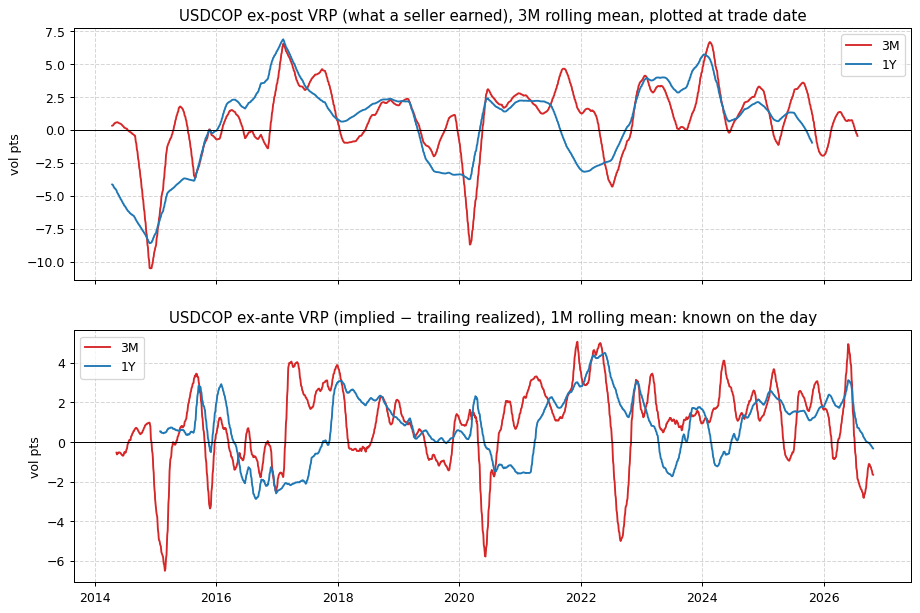

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for t, colr in [("3M", "#d62728"), ("1Y", "#1f77b4")]:
    x = V["COP"][t]
    axes[0].plot(x.vrp_expost.rolling(63).mean(), color=colr, label=t)
    axes[1].plot(x.vrp_exante.rolling(21).mean(), color=colr, label=t)
axes[0].set_title("USDCOP ex-post VRP (what a seller earned), 3M rolling mean, plotted at trade date")
axes[1].set_title("USDCOP ex-ante VRP (implied − trailing realized), 1M rolling mean: known on the day")
for a in axes: a.axhline(0, color="k", lw=.8); a.legend(); a.set_ylabel("vol pts")
plt.show()

for t in TENORS:
    x = V["COP"][t].dropna()
    print(f"{t}: correlation of ex-ante signal with ex-post outcome = {x.vrp_exante.corr(x.vrp_expost):+.2f}")

The premium moves in regimes: deeply negative in the 2014–15 oil collapse, solidly positive in 2016–18 and 2023–24, with sharp losses around Covid and 2022.

The bottom line of the cell is important: the ex-ante VRP barely predicts the ex-post VRP. "Implied is above recent realized" is not, on its own, a reason to sell.

## 8. Across LatAm, and the equal-vega basket

      mean_vrp  median_vrp  hit_rate  worst  sharpe_vol  sharpe_se  sharpe_var
pair                                                                          
COP       0.73        1.09     65.71 -12.96        0.46       0.30        0.16
MXN       0.72        1.12     68.08 -21.25        0.40       0.29        0.04
BRL       0.27        0.84     63.25 -14.52        0.15       0.28       -0.07
CLP       0.54        0.85     65.32 -13.16        0.35       0.29        0.11
PEN       0.67        0.90     70.13 -11.96        0.49       0.30        0.01


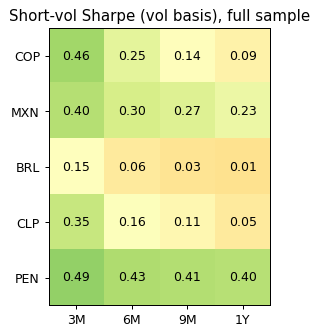

In [12]:
allstats = pd.DataFrame([vrp_stats(p, t) for p in PAIRS for t in TENORS])
piv = allstats.pivot(index="pair", columns="tenor", values="sharpe_vol")[list(TENORS)].loc[PAIRS]

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(piv.values, cmap="RdYlGn", vmin=-.6, vmax=.9)
ax.set_xticks(range(4), piv.columns); ax.set_yticks(range(5), piv.index)
for i in range(5):
    for j in range(4): ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center")
ax.set_title("Short-vol Sharpe (vol basis), full sample"); ax.grid(False); plt.show()

print(allstats[allstats.tenor == "3M"].set_index("pair").drop(columns="tenor").round(2))

* 3M is usually the best tenor to sell, except in PEN, where the premium holds out the curve (central-bank smoothing keeps realized low).
* BRL has offered almost nothing.
* Every pair's worst trade is −12 to −21 vol points: these are crash-insurance premia.

### The equal-vega basket

**Idea:** sell the same amount of vega (say \$4,000 per vol point, i.e. a 3M straddle on about \$1m) in all five pairs. Because the pairs' premia are not perfectly correlated, the combination is smoother than any single pair in normal times.

**What it is not:** relative value. Five short-vol positions add up to a directional bet that LatAm stays calm. In a regional or global risk-off they all lose together.

In [13]:
B3 = pd.DataFrame({p: V[p]["3M"].vrp_expost for p in PAIRS}).dropna()
basket = B3.mean(axis=1).to_frame("vrp_expost")

def quick_sharpe(series):
    return nonoverlap_sharpe(series.to_frame("v"), 3, "v")

print("Non-overlapping 3M Sharpe:")
for p in PAIRS: print(f"  {p}: {quick_sharpe(B3[p]):.2f}")
print(f"  Equal-vega basket: {quick_sharpe(basket.vrp_expost):.2f}")

print("\nCorrelation of 3M VRP across pairs (non-overlapping sample):")
print(B3.iloc[::63].corr().round(2))
print("\nWorst basket trades by entry date:")
print(basket.vrp_expost.nsmallest(3).round(2))

Non-overlapping 3M Sharpe:
  COP: 0.46
  MXN: 0.40
  BRL: 0.14
  CLP: 0.35
  PEN: 0.54
  Equal-vega basket: 0.56

Correlation of 3M VRP across pairs (non-overlapping sample):
      COP   MXN   BRL   CLP   PEN
COP  1.00  0.58  0.62  0.43  0.14
MXN  0.58  1.00  0.59  0.40  0.13
BRL  0.62  0.59  1.00  0.34  0.08
CLP  0.43  0.40  0.34  1.00  0.22
PEN  0.14  0.13  0.08  0.22  1.00

Worst basket trades by entry date:
date
2020-02-21   -11.19
2020-02-19   -11.14
2020-02-18   -11.09
Name: vrp_expost, dtype: float64


**Equal vega is not equal risk.** One vol point is a much larger relative move in PEN (implied ~9) than in BRL (~16), and BRL's premium swings far more. Alternatives a vol trader may ask about:

* **Inverse-volatility (risk parity):** weight each pair by 1 / standard deviation of its VRP.
* **Percentage vega:** vega × implied vol, so a 10% relative move in vol costs the same in each pair.
* **Equal gamma:** equalize the exposure to realized moves rather than to implied.

Present equal vega as a deliberately naive benchmark, not an optimized portfolio.

**Try it:** weight the basket by `1 / B3.std()` and compare the Sharpe. Then ask yourself why that comparison is still slightly unfair (the weights use the whole sample's volatility, which you would not have known in 2014).

## 9. Relative value: a vega-neutral long/short backtest

Now the actual RV question: can we **sell the richest** pairs and **buy the cheapest**, with zero net vega, so the common LatAm risk largely cancels?

**Rules**
* Every ~21 trading days, open a 3M position in each pair. Sell vega in the 2 pairs the signal ranks richest (weight −0.5 each), buy vega in the 2 cheapest (+0.5 each). Net vega = 0.
* Hold each position to expiry. Monthly entries mean three cohorts overlap at any time.
* Charge half the bid/offer at entry. **These spreads are my illustrative assumptions, not dealer quotes**, so results are shown at 0×, 1× and 2×.

**Daily marking.** A position struck at implied $K$ over $T$ trading days is marked like a vol swap. After $e$ days:

$$V_t = \frac{e}{T}\,(\text{RV}_{\text{so far}} - K) + \frac{T-e}{T}\,(\text{IV}^{3M}_t - K)$$

The first term is what has already been realized; the second marks the remaining life at today's implied. At entry $V = 0$; at expiry $V = \text{RV} - K$. Daily P&L is the change in $V$. Marking daily matters because short vega loses on the day implied spikes, long before expiry.

**Approximations:** constant-maturity 3M implied marks the remaining life (ignores roll-down along the vol curve); vol-swap rather than straddle payoff; delta-hedging costs ignored.

Everything is put on one common weekday calendar; holiday zero-returns are excluded from the day count so realized vol is not understated.

In [14]:
TENOR, MONTHS = "3M", 3
START = "2015-01-01"            # 2014 is warm-up for the signals
REBAL_EVERY, N_SIDE = 21, 2
HALF_SPREAD = {"COP": 0.40, "MXN": 0.15, "BRL": 0.25, "CLP": 0.35, "PEN": 0.50}   # ILLUSTRATIVE

spot_c = pd.DataFrame({p: data[p]["spot"] for p in PAIRS}).ffill()
iv_c   = pd.DataFrame({p: data[p][f"atm_{TENOR}"] for p in PAIRS}).ffill()
dates  = spot_c.index; NOBS = len(dates)
ret_c  = np.log(spot_c).diff().fillna(0.0)
live   = (ret_c != 0).astype(float)
c_r2   = np.vstack([np.zeros(len(PAIRS)), np.cumsum(ret_c.values ** 2, axis=0)])
c_n    = np.vstack([np.zeros(len(PAIRS)), np.cumsum(live.values, axis=0)])

def rv_rows(i0, i1):
    # realized vol over rows i0+1..i1 for all pairs
    n = c_n[i1 + 1] - c_n[i0 + 1]
    return np.sqrt((c_r2[i1 + 1] - c_r2[i0 + 1]) / np.maximum(n, 1) * ANN) * 100

expiry = np.array([dates.searchsorted(d + pd.DateOffset(months=MONTHS)) for d in dates])
expiry = np.where(expiry >= NOBS, -1, expiry)
trail = pd.DataFrame(np.nan, index=dates, columns=PAIRS); expost = trail.copy()
for i, d in enumerate(dates):
    if d - pd.DateOffset(months=MONTHS) >= dates[0]:
        trail.iloc[i] = rv_rows(dates.searchsorted(d - pd.DateOffset(months=MONTHS)), i)
    if expiry[i] > 0:
        expost.iloc[i] = rv_rows(i, expiry[i])
print("calendar ready:", dates[0].date(), "to", dates[-1].date(), f"({NOBS} rows)")

calendar ready: 2014-01-01 to 2026-10-26 (3344 rows)


### Signals (higher = richer = sell)

All use only information available on the trade date.

1. **Ex-ante VRP**: implied − trailing 3M realized, in vol points.
2. **Implied / realized ratio**: the same idea scaled by vol level, so a 1-point gap in PEN counts more than in BRL.
3. **Implied percentile vs own realized history**: where today's implied sits within every 3M realized vol the pair has produced so far (expanding window).
4. **Historical VRP %**: the pair's average past premium as a % of implied, using only trades that had already expired.
5. **Implied z-score vs its own past year**: is implied high relative to where implied has been recently?

In [15]:
rv63 = (ret_c.pow(2).rolling(63).sum() / live.rolling(63).sum() * ANN).pow(.5) * 100

def build_signals():
    S = {}
    S["Ex-ante VRP"] = iv_c - trail
    S["IV/RV ratio"] = iv_c / trail
    pct = pd.DataFrame(np.nan, index=dates, columns=PAIRS)
    for j, p in enumerate(PAIRS):
        h, v = rv63[p].values, iv_c[p].values
        for i in range(NOBS):
            past = h[: i + 1]; past = past[~np.isnan(past)]
            if len(past) >= 250: pct.iat[i, j] = (past < v[i]).mean()
    S["IV pct vs own history"] = pct
    hist = pd.DataFrame(np.nan, index=dates, columns=PAIRS)
    vrp_pct = ((iv_c - expost) / iv_c).values
    for i in range(NOBS):
        ok = (expiry[: i + 1] >= 0) & (expiry[: i + 1] <= i)          # only expired trades
        if ok.sum() >= 120: hist.iloc[i] = np.nanmean(vrp_pct[: i + 1][ok], axis=0)
    S["Historical VRP"] = hist
    S["IV z-score (1y)"] = (iv_c - iv_c.rolling(252).mean()) / iv_c.rolling(252).std()
    return S

signals = build_signals()
print("today's signal ranks (5 = richest):")
print(pd.DataFrame({k: s.iloc[-1].rank() for k, s in signals.items()}).T)

today's signal ranks (5 = richest):
                       COP  MXN  BRL  CLP  PEN
Ex-ante VRP            2.0  4.0  1.0  3.0  5.0
IV/RV ratio            2.0  4.0  1.0  3.0  5.0
IV pct vs own history  2.0  3.0  1.0  4.0  5.0
Historical VRP         3.0  4.0  1.0  2.0  5.0
IV z-score (1y)        1.0  5.0  4.0  2.0  3.0


In [16]:
def run(weights_fn, cost_mult=1.0):
    pnl = np.zeros((NOBS, len(PAIRS))); book = []
    spread = np.array([HALF_SPREAD[p] for p in PAIRS])
    for i in range(dates.searchsorted(pd.Timestamp(START)), NOBS, REBAL_EVERY):
        j = expiry[i]
        if j < 0: break
        w = weights_fn(i)
        if w is None: continue
        K = iv_c.values[i]; T = c_n[j + 1] - c_n[i + 1]; V_prev = np.zeros(len(PAIRS))
        for d in range(i + 1, j + 1):
            f = (c_n[d + 1] - c_n[i + 1]) / T
            V = f * (rv_rows(i, d) - K) + (1 - f) * (iv_c.values[d] - K) if d < j else rv_rows(i, j) - K
            pnl[d] += w * (V - V_prev); V_prev = V
        pnl[i] -= np.abs(w) * spread * cost_mult
        book.append((dates[i], w))
    return pd.DataFrame(pnl, index=dates, columns=PAIRS).loc[START:], book

def long_short(sig):
    def f(i):
        s = sig.iloc[i]
        if s.isna().any(): return None
        rk = s.rank().values; w = np.zeros(len(PAIRS))
        w[rk > len(PAIRS) - N_SIDE] = -1 / N_SIDE       # richest: sell vega
        w[rk <= N_SIDE] = +1 / N_SIDE                   # cheapest: buy vega
        return w
    return f

short_basket = lambda i: np.full(len(PAIRS), -1 / len(PAIRS))

def newey_west_se(x, lags=3):
    x = np.asarray(x) - np.mean(x); n = len(x); s = x @ x / n
    for L in range(1, lags + 1): s += 2 * (1 - L / (lags + 1)) * (x[L:] @ x[:-L]) / n
    return np.sqrt(s / n)

def perf(daily, ref=None):
    m = daily.sum(axis=1).resample("ME").sum(); eq = daily.sum(axis=1).cumsum()
    out = dict(ann_pnl=m.mean() * 12, sharpe=m.mean() / m.std() * np.sqrt(12),
               t_stat=m.mean() / newey_west_se(m.values), hit_months=(m > 0).mean() * 100,
               max_drawdown=(eq - eq.cummax()).min(), worst_month=m.min())
    if ref is not None: out["corr_to_short_basket"] = m.corr(ref.sum(axis=1).resample("ME").sum())
    return out

**Units.** P&L is in vol points × vega units. If one vega unit is \$10,000 per vol point, an annual P&L of 5 is about \$50,000 a year. Sharpe ratios and t-stats do not depend on the unit.

The next cell runs every signal at three cost levels (a minute or two).

In [17]:
base, _ = run(short_basket)
rows, curves, books = [], {}, {}
for name, sig in signals.items():
    for cm in [0, 1, 2]:
        d, book = run(long_short(sig), cm)
        rows.append(dict(signal=name, costs=f"{cm}x", **perf(d, base)))
        if cm == 1: curves[name], books[name] = d, book
for cm in [0, 1, 2]:
    d, _ = run(short_basket, cm); rows.append(dict(signal="Short-all basket", costs=f"{cm}x", **perf(d)))
    if cm == 1: curves["Short-all basket"] = d
results = pd.DataFrame(rows).set_index(["signal", "costs"])
print(results.round(2))

                             ann_pnl  sharpe  t_stat  hit_months  max_drawdown  worst_month  corr_to_short_basket
signal                costs                                                                                      
Ex-ante VRP           0x        6.58    0.53    1.74       57.75        -39.04       -20.06                  0.24
                      1x       -1.52   -0.12   -0.40       47.89        -47.59       -20.63                  0.24
                      2x       -9.61   -0.78   -2.57       40.85       -126.21       -21.21                  0.24
IV/RV ratio           0x        6.54    0.50    1.62       55.63        -48.66       -20.65                  0.19
                      1x       -1.62   -0.12   -0.40       46.48        -60.37       -21.28                  0.19
                      2x       -9.78   -0.76   -2.44       35.21       -132.24       -21.90                  0.19
IV pct vs own history 0x       14.18    1.06    3.11       65.49        -20.83       -12

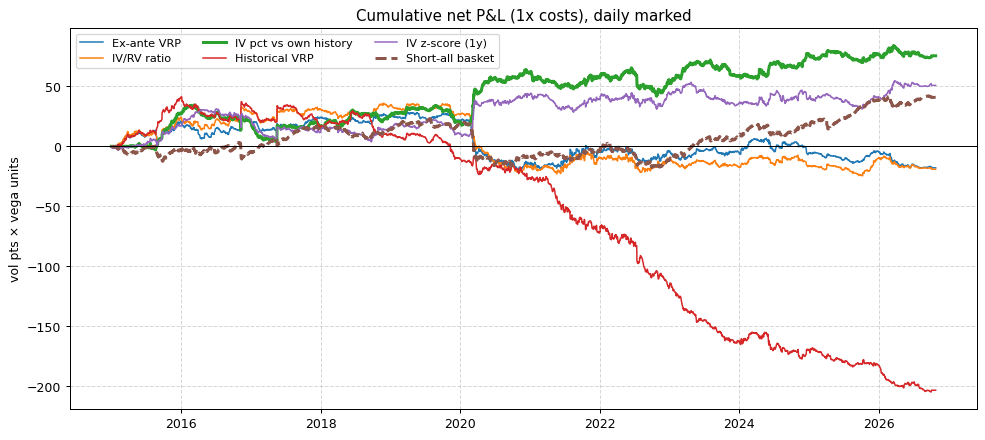

In [18]:
fig, ax = plt.subplots(figsize=(13, 5.5))
for k, d in curves.items():
    ax.plot(d.sum(axis=1).cumsum(), lw=2.4 if k in ("IV pct vs own history", "Short-all basket") else 1.2,
            ls="--" if k == "Short-all basket" else "-", label=k)
ax.axhline(0, color="k", lw=.8); ax.legend(ncol=3, fontsize=9)
ax.set_title("Cumulative net P&L (1x costs), daily marked"); ax.set_ylabel("vol pts × vega units"); plt.show()

**Reading the table**

* **Costs decide everything.** Rebuilding the book monthly pays the spread on every unit of vega, cutting about 0.6 from every Sharpe. The intuitive ex-ante VRP signal goes from about 0.5 to slightly negative.
* **"IV pct vs own history" is the only signal with a convincing pre-cost edge** (Sharpe ~1.0, t ~3). After 1× costs it is ~0.5 with t ~1.4: not statistically significant.
* **Historical VRP loses steadily.** Selling the pairs that were richest in the past (PEN, MXN) and buying the cheapest (BRL, CLP) did not work. Past richness did not persist.
* **Multiple testing.** Five signals were tried and we are looking at the best one. A t-stat of 3 found that way is suggestive, not proof.

## 10. Diagnosing the result: where does the P&L come from?

Share of entries short / long vega by pair:
        COP   MXN  BRL   CLP   PEN
short  0.13  0.45  0.1  0.64  0.70
long   0.43  0.41  0.8  0.11  0.23

Net P&L by pair: {'COP': -30.6, 'MXN': 30.8, 'BRL': -2.1, 'CLP': 29.5, 'PEN': 47.8}

Sharpe if you just held the average positions: -0.53
Sharpe of the signal (dynamic):                 0.48
Net Sharpe excluding 2015 and 2020: 0.05


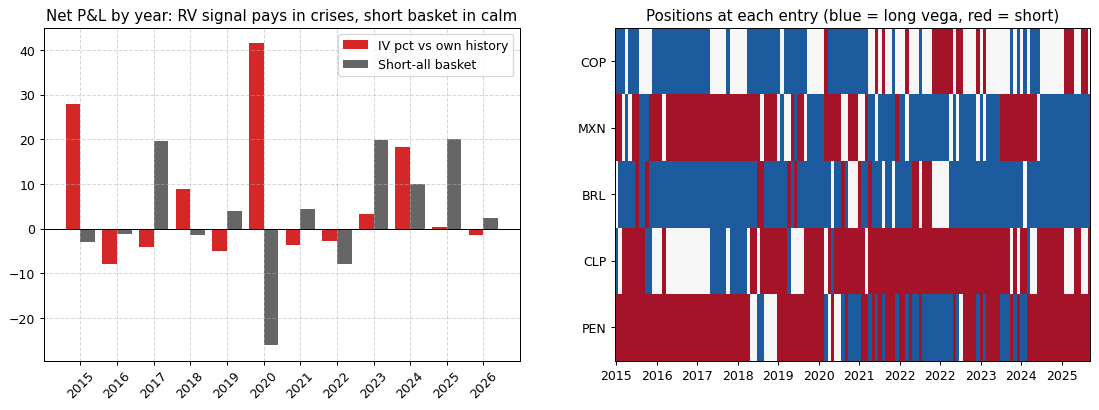

In [19]:
best = "IV pct vs own history"
d = curves[best]; b = curves["Short-all basket"]
W = pd.DataFrame([w for _, w in books[best]], index=[t for t, _ in books[best]], columns=PAIRS)

print("Share of entries short / long vega by pair:")
print(pd.DataFrame({"short": (W < 0).mean(), "long": (W > 0).mean()}).T.round(2))
print("\nNet P&L by pair:", d.sum().round(1).to_dict())

static, _ = run(lambda i: W.mean().values, 1)          # hold the average positions constant
print(f"\nSharpe if you just held the average positions: {perf(static)['sharpe']:.2f}")
print(f"Sharpe of the signal (dynamic):                 {perf(d)['sharpe']:.2f}")

py = d.sum(axis=1).groupby(d.index.year).sum(); by = b.sum(axis=1).groupby(b.index.year).sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(py))
axes[0].bar(x - .2, py, .4, color="#d62728", label=best); axes[0].bar(x + .2, by, .4, color="k", alpha=.6, label="Short-all basket")
axes[0].set_xticks(x, py.index, rotation=45); axes[0].axhline(0, color="k", lw=.8); axes[0].legend()
axes[0].set_title("Net P&L by year: RV signal pays in crises, short basket in calm")
axes[1].imshow(W.T.values, aspect="auto", cmap="RdBu", vmin=-.6, vmax=.6, interpolation="nearest")
axes[1].set_yticks(range(5), PAIRS); tk = np.arange(0, len(W), 12); axes[1].set_xticks(tk, [W.index[i].year for i in tk])
axes[1].set_title("Positions at each entry (blue = long vega, red = short)"); axes[1].grid(False)
plt.show()

m = d.sum(axis=1).resample("ME").sum(); calm = m[~m.index.year.isin([2015, 2020])]
print(f"Net Sharpe excluding 2015 and 2020: {calm.mean() / calm.std() * np.sqrt(12):.2f}")

**What the signal is really doing**

* It is long BRL vol most of the time. BRL's realized history contains huge spikes, so today's implied usually looks low against it. It is mostly short PEN and CLP, whose implied looks high against a calm realized history.
* Holding the average positions constant loses money. The edge comes from **timing**, not from a hidden fixed tilt.
* Almost all of the net P&L came in 2015 and 2020, when the pairs with fat tails blew out. Excluding those years, the net Sharpe is roughly zero.

So it behaves like **crisis insurance**: negatively correlated with the short-vol basket, earning when the basket loses. That suggests one more idea.

In [20]:
p = d.sum(axis=1); bb = b.sum(axis=1)
for lam in [0, 0.25, 0.5, 1.0]:
    x = bb + lam * p; mm = x.resample("ME").sum()
    print(f"short basket + {lam:.2f} × RV overlay: Sharpe {mm.mean() / mm.std() * np.sqrt(12):.2f}, worst month {mm.min():6.1f}")

short basket + 0.00 × RV overlay: Sharpe 0.28, worst month  -24.6
short basket + 0.25 × RV overlay: Sharpe 0.42, worst month  -19.6
short basket + 0.50 × RV overlay: Sharpe 0.55, worst month  -14.6
short basket + 1.00 × RV overlay: Sharpe 0.65, worst month  -20.4


Adding half a unit of the RV signal to the short-vol basket roughly doubles the Sharpe (0.28 → 0.55) and cuts the worst month (−24.6 → −14.6).

**But the mix was chosen after seeing the data.** This is a hypothesis to test going forward, not a result.

## 11. Before you show this to a vol trader

**State these limits yourself:**

1. **Costs are assumptions.** Ask what real bid/offers are in each pair; it is the single number that decides whether any of this is tradable.
2. **Proxy P&L.** Implied − realized approximates a delta-hedged straddle; section 4 showed the path-dependent scatter around it. Vol swaps are thin in these pairs.
3. **Marking.** Constant-maturity 3M implied ignores roll-down along the vol curve.
4. **Fixings.** NDF options settle on fixings (TRM, PTAX…), not Bloomberg closes.
5. **Skew ignored.** Everything is ATM. A short straddle book is also short the wings.
6. **Statistics.** ~48 independent 3M trades; Sharpe standard error ~0.29; five signals tested.
7. **Events.** Elections and policy shocks drive the worst losses. BRL implied on 26 Oct 2026 looks stale after the runoff move.

**The defensible claim:** cross-sectional LatAm vol RV does not clear realistic costs on this data. One signal shows a crisis-concentrated gross edge that is negatively correlated with short vol, so it is worth testing as a tail hedge for a short-vol book.

### Exercises

1. **Tenor.** Set `TENOR, MONTHS = "6M", 6` in section 9 and rerun. Costs are paid once per position, so longer tenors spread them over more time. Which signals improve?
2. **Concentration.** Set `N_SIDE = 1` (one pair each side). Does the best signal still work?
3. **Breakeven costs.** Find the cost multiple at which "IV pct vs own history" has zero Sharpe.
4. **Risk weighting.** Replace `±1/N_SIDE` with weights scaled by 1 / each pair's trailing VRP volatility. Use only past data.
5. **Variance basis.** Change the marking to variance-swap terms and see which signals survive.
6. **Skew signals.** Build a signal from the RR percentile (`data[p]["rr_3M"]`) and test it the same way.